In [111]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"


In [91]:
import numpy as np
import pandas as pd
import os
import json
import csv

train_json_path = '/home/jeremy/HW/train.json'
train_csv_path = '/home/jeremy/HW/train.csv'

with open(train_json_path, 'r', encoding='utf-8') as file:
    data = json.load(file)

with open(train_csv_path, 'w', newline='', encoding='utf-8') as file:
    csv_writer = csv.writer(file)
    csv_writer.writerow(data[0].keys())
    for item in data:
        csv_writer.writerow(item.values())

train_df = pd.read_csv(train_csv_path)
train_df

,rating,title,text,helpful_vote,verified_purchase
0,1.0,"Bristles fall out, also very stiff",The boar bristles fall out. The plastic bristl...,0,True
1,3.0,Moldy tape,"I mean, 4 out of 6 tapes were alright… the oth...",3,True
2,5.0,Be prepared to wait,I did not like having to wait six months but t...,0,True
3,2.0,"Creases up terribly, but sparkly!","Pearly shine and lovely packaging. However, I ...",0,True
4,5.0,"Love these!! So pretty not too long, just wish...",Love these!! So pretty my favorite color & not...,0,True
...,...,...,...,...,...
34995,4.0,Works well,They work well. The only thing is that they le...,0,True
34996,1.0,allergic,I'm allergic to this item. (My face is itchy a...,0,False
34997,1.0,No good,It doesn't wo,1,True
34998,2.0,at the end you end up using more acetone to re...,fits as expected but its flimsy and the aceton...,0,True


In [77]:
from sklearn.model_selection import train_test_split

# Fill missing values in 'title' and 'text' columns with empty strings
train_df['title'] = train_df['title'].fillna('')
train_df['text'] = train_df['text'].fillna('')

# Combine 'title' and 'text' into a single column
train_df['review'] = train_df['title'] + " " + train_df['text']

# Cast the 'rating' to integer type as the model expects integer labels
train_df['rating'] = train_df['rating'].astype(int)

train_data, val_data = train_test_split(train_df, test_size=0.1, random_state=42)

In [ ]:
from transformers import BertTokenizer

# Load the tokenizer for the BERT model
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

def tokenize_data(data, max_length=512):
    return tokenizer(data['review'].tolist(),
                     max_length=max_length,
                     padding='max_length',
                     truncation=True,
                     return_tensors='pt')

train_encodings = tokenize_data(train_data)
val_encodings = tokenize_data(val_data)

# Adjust labels to start from 0 by subtracting 1
train_labels = [label - 1 for label in train_data['rating'].tolist()]
val_labels = [label - 1 for label in val_data['rating'].tolist()]


Token indices sequence length is longer than the specified maximum sequence length for this model (874 > 512). Running this sequence through the model will result in indexing errors


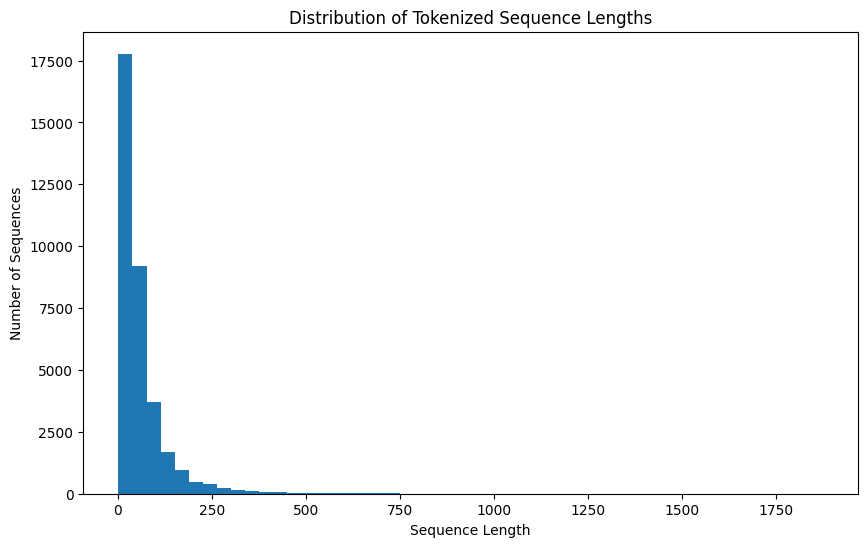

Maximum length: 1875
Average length: 60


In [61]:
import matplotlib.pyplot as plt

token_lengths = []
reviews = train_df['review'].tolist()
for review in reviews:
    tokens = tokenizer.encode(review, add_special_tokens=True)
    token_lengths.append(len(tokens))

plt.figure(figsize=(10, 6))
plt.hist(token_lengths, bins=50)
plt.title('Distribution of Tokenized Sequence Lengths')
plt.xlabel('Sequence Length')
plt.ylabel('Number of Sequences')
plt.show()

max_length = max(token_lengths)
average_length = int(sum(token_lengths) / len(token_lengths))
print(f"Maximum length: {max_length}")
print(f"Average length: {average_length}")

In [79]:
from transformers import BertForSequenceClassification, AdamW
from torch.utils.data import DataLoader, TensorDataset, RandomSampler, SequentialSampler
import torch
from torch.nn import DataParallel

# Convert the lists of inputs and labels into tensors and create a dataset object
train_dataset = TensorDataset(train_encodings['input_ids'], train_encodings['attention_mask'], torch.tensor(train_labels))
val_dataset = TensorDataset(val_encodings['input_ids'], val_encodings['attention_mask'], torch.tensor(val_labels))

# Loaders for handling batches of data
train_loader = DataLoader(train_dataset, batch_size=16, sampler=RandomSampler(train_dataset))
val_loader = DataLoader(val_dataset, batch_size=16, sampler=SequentialSampler(val_dataset))

In [ ]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=5)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.device_count() > 1:
    print(f"Let's use {torch.cuda.device_count()} GPUs!")
    model = DataParallel(model)

model.to('cuda')


In [ ]:
from ranger21 import Ranger21
from torch.optim.lr_scheduler import StepLR
optimizer = Ranger21(model.parameters(), lr=2e-5, num_epochs=50, num_batches_per_epoch=len(train_loader))
# optimizer = AdamW(model.parameters(), lr=2e-5)
scheduler = StepLR(optimizer, step_size=4, gamma=0.01)

batch_size = 16
def train(epoch, model, train_loader, optimizer):
    model.train()
    total_loss = 0
    for batch_idx, data in enumerate(train_loader, 0):
        inputs = {'input_ids': data[0].to(device), 'attention_mask': data[1].to(device), 'labels': data[2].to(device)}
        optimizer.zero_grad()
        outputs = model(**inputs)
        loss = outputs.loss.mean()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        torch.cuda.empty_cache()
    return total_loss / len(train_loader)


In [84]:
from sklearn.metrics import f1_score
def evaluate(model, val_loader):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for data in val_loader:
            inputs = {'input_ids': data[0].to(device), 'attention_mask': data[1].to(device), 'labels': data[2].to(device)}
            outputs = model(**inputs)
            loss = outputs.loss.mean()
            total_loss += loss.item()
            logits = outputs.logits.detach().cpu().numpy()
            label_ids = inputs['labels'].cpu().numpy()
            all_preds.extend(np.argmax(logits, axis=1))
            all_labels.extend(label_ids)
            torch.cuda.empty_cache()
    avg_loss = total_loss / len(val_loader)
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, f1

In [85]:
# Parameters for Early Stopping
patience = 3  # Number of epochs to wait after last time validation loss improved.
best_val_loss = float('inf')
counter = 0

for epoch in range(1, 50):  # Maximum number of epochs
    train_loss = train(epoch, model, train_loader, optimizer)
    scheduler.step()
    val_loss, val_f1 = evaluate(model, val_loader)
    print(f'Epoch: {epoch}, Training Loss: {train_loss}, Validation Loss: {val_loss}, Validation F1: {val_f1}')

    # Check if the validation loss improved
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping with best validation loss:", best_val_loss)
        break

/home/jeremy/.conda/envs/master/lib/python3.9/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


params size saved
total param groups = 1
total params in groups = 201
Epoch: 1, Training Loss: 1.3640817356267032, Validation Loss: 1.0019263886425593, Validation F1: 0.5575200613464176


/home/jeremy/.conda/envs/master/lib/python3.9/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '



** Ranger21 update = Warmup complete - lr set to 2e-05

Epoch: 2, Training Loss: 0.9098054433214053, Validation Loss: 0.8982329982328633, Validation F1: 0.602207152773987


/home/jeremy/.conda/envs/master/lib/python3.9/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


...

Epoch: 4, Training Loss: 0.7364418405969474, Validation Loss: 0.889876875022775, Validation F1: 0.622647256129192


/home/jeremy/.conda/envs/master/lib/python3.9/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Epoch: 5, Training Loss: 0.6567330212006416, Validation Loss: 0.8953641217593189, Validation F1: 0.6266251905492071


/home/jeremy/.conda/envs/master/lib/python3.9/site-packages/torch/nn/parallel/_functions.py:68: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn('Was asked to gather along dimension 0, but all '


Epoch: 6, Training Loss: 0.6499033360129507, Validation Loss: 0.9015353447226084, Validation F1: 0.6270893667151695
Early stopping with best validation loss: 0.8771498920438496


In [86]:
torch.save(model.module.state_dict(), '/home/jeremy/HW/model_newlr2.pth')
print("Model saved successfully!")

Model saved successfully!


In [ ]:
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=5)
state_dict = torch.load('/home/jeremy/HW/model_newlr2.pth')
new_state_dict = {k.replace('module.', ''): v for k, v in state_dict.items()}
model.load_state_dict(new_state_dict)
model.to(device)

In [ ]:
test_json_path = '/home/jeremy/HW/test.json'
test_csv_path = '/home/jeremy/HW/test.csv'

with open(test_json_path, 'r', encoding='utf-8') as file:
    data = json.load(file)

with open(test_csv_path, 'w', newline='', encoding='utf-8') as file:
    csv_writer = csv.writer(file)
    csv_writer.writerow(data[0].keys())
    for item in data:
        csv_writer.writerow(item.values())

test_df = pd.read_csv(test_csv_path)

In [88]:
test_df['title'] = test_df['title'].fillna('')
test_df['text'] = test_df['text'].fillna('')

test_df['review'] = test_df['title'] + " " + test_df['text']

test_df['review'] = test_df['review'].astype(str)
test_texts = test_df['review'].tolist()

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

test_encodings = tokenizer(test_df['review'].tolist(),
                           truncation=True,
                           padding=True,
                           max_length=512,
                           return_tensors="pt")

test_encodings = {key: val.to(device) for key, val in test_encodings.items()}

batch_size = 16

model.eval()

predictions = []

for i in range(0, len(test_texts), batch_size):
    batch_texts = test_texts[i:i+batch_size]
    encodings = tokenizer(batch_texts, truncation=True, padding=True, max_length=512, return_tensors="pt").to(device)
    
    with torch.no_grad():
        outputs = model(**encodings)
        batch_preds = torch.argmax(outputs.logits, dim=1)
        predictions.extend(batch_preds.cpu().numpy())
    
    torch.cuda.empty_cache()

In [90]:
predictions = [p + 1 for p in predictions]

index_list = [f'index_{i}' for i in range(len(predictions))]

results_df = pd.DataFrame({
    'index': index_list,
    'rating': predictions
})

results_df = results_df[['index', 'rating']]
results_df.to_csv('submission_newlr2.csv', index=False)